1.INSTALL THE REQUIRED LIBRARIES . THIS IS THE FIRST STEP IN THE MACHINE LEARNING



In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    recall_score
)

2.LOAD THE DATASET


Dataset Shape: (8124, 23)


,class,cap-shape,cap-surface,cap-color,bruises,odor,gill-attachment,gill-spacing,gill-size,gill-color,...,stalk-surface-below-ring,stalk-color-above-ring,stalk-color-below-ring,veil-type,veil-color,ring-number,ring-type,spore-print-color,population,habitat
0,p,x,s,n,t,p,f,c,n,k,...,s,w,w,p,w,o,p,k,s,u
1,e,x,s,y,t,a,f,c,b,k,...,s,w,w,p,w,o,p,n,n,g
2,e,b,s,w,t,l,f,c,b,n,...,s,w,w,p,w,o,p,n,n,m
3,p,x,y,w,t,p,f,c,n,n,...,s,w,w,p,w,o,p,k,s,u
4,e,x,s,g,f,n,f,w,b,k,...,s,w,w,p,w,o,e,n,a,g


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8124 entries, 0 to 8123
Data columns (total 23 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   class                     8124 non-null   object
 1   cap-shape                 8124 non-null   object
 2   cap-surface               8124 non-null   object
 3   cap-color                 8124 non-null   object
 4   bruises                   8124 non-null   object
 5   odor                      8124 non-null   object
 6   gill-attachment           8124 non-null   object
 7   gill-spacing              8124 non-null   object
 8   gill-size                 8124 non-null   object
 9   gill-color                8124 non-null   object
 10  stalk-shape               8124 non-null   object
 11  stalk-root                8124 non-null   object
 12  stalk-surface-above-ring  8124 non-null   object
 13  stalk-surface-below-ring  8124 non-null   object
 14  stalk-color-above-ring  

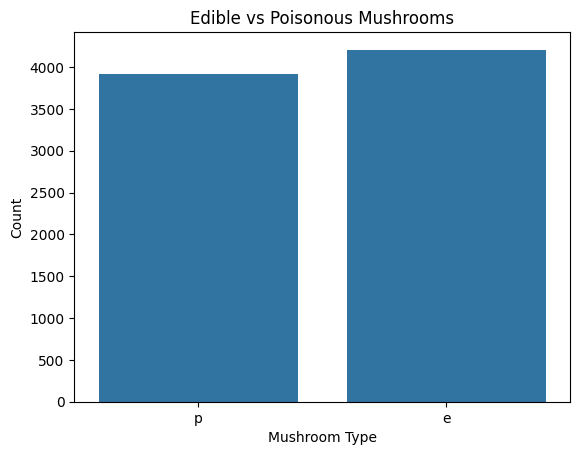

In [6]:
columns = [
    'class', 'cap-shape', 'cap-surface', 'cap-color', 'bruises', 'odor',
    'gill-attachment', 'gill-spacing', 'gill-size', 'gill-color',
    'stalk-shape', 'stalk-root', 'stalk-surface-above-ring',
    'stalk-surface-below-ring', 'stalk-color-above-ring',
    'stalk-color-below-ring', 'veil-type', 'veil-color', 'ring-number',
    'ring-type', 'spore-print-color', 'population', 'habitat'
]

# Replace 'your_filename.csv' with the exact filename you used earlier
df = pd.read_csv('/content/agaricus-lepiota.data', header=None, names=columns)

print("Dataset Shape:", df.shape)
display(df.head())

df.info()


print(df.isnull().sum())

print(df["class"].value_counts())

sns.countplot(data=df, x="class")

plt.title("Edible vs Poisonous Mushrooms")
plt.xlabel("Mushroom Type")
plt.ylabel("Count")

plt.show()

In [7]:
X = df.drop("class", axis=1)

y = df["class"].map({
    "e": 0,
    "p": 1
})

print(X.head())
print(y.head())

  cap-shape cap-surface cap-color bruises odor gill-attachment gill-spacing  \
0         x           s         n       t    p               f            c   
1         x           s         y       t    a               f            c   
2         b           s         w       t    l               f            c   
3         x           y         w       t    p               f            c   
4         x           s         g       f    n               f            w   

  gill-size gill-color stalk-shape  ... stalk-surface-below-ring  \
0         n          k           e  ...                        s   
1         b          k           e  ...                        s   
2         b          n           e  ...                        s   
3         n          n           e  ...                        s   
4         b          k           t  ...                        s   

  stalk-color-above-ring stalk-color-below-ring veil-type veil-color  \
0                      w                    

In [8]:
preprocessor = ColumnTransformer(
    transformers=[
        ("categorical", OneHotEncoder(handle_unknown="ignore"), X.columns)
    ]
)

In [9]:
X_train_val, X_test, y_train_val, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

X_train, X_val, y_train, y_val = train_test_split(
    X_train_val, y_train_val,
    test_size=0.25,
    random_state=42,
    stratify=y_train_val
)

print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Testing:", X_test.shape)

Training: (4874, 22)
Validation: (1625, 22)
Testing: (1625, 22)


In [10]:
dt_model = Pipeline([
    ("preprocessing", preprocessor),
    ("classifier", DecisionTreeClassifier(
        random_state=42,
        class_weight="balanced"
    ))
])

dt_model.fit(X_train, y_train)

print("Decision Tree Training Completed!")

Decision Tree Training Completed!


In [11]:
rf_model = Pipeline([
    ("preprocessing", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=300,
        random_state=42,
        class_weight="balanced"
    ))
])

rf_model.fit(X_train, y_train)

print("Random Forest Training Completed!")

Random Forest Training Completed!



 Decision Tree
Threshold: 1.0
Accuracy: 1.0
Poisonous Sensitivity: 1.0

Classification Report:
              precision    recall  f1-score   support

      Edible       1.00      1.00      1.00       842
   Poisonous       1.00      1.00      1.00       783

    accuracy                           1.00      1625
   macro avg       1.00      1.00      1.00      1625
weighted avg       1.00      1.00      1.00      1625



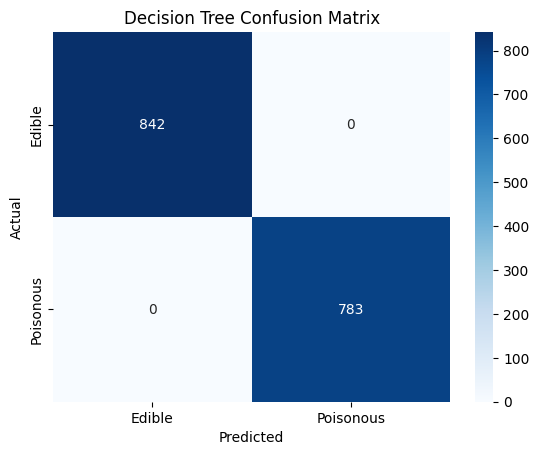


 Random Forest
Threshold: 0.9566666666666667
Accuracy: 0.9981538461538462
Poisonous Sensitivity: 0.9961685823754789

Classification Report:
              precision    recall  f1-score   support

      Edible       1.00      1.00      1.00       842
   Poisonous       1.00      1.00      1.00       783

    accuracy                           1.00      1625
   macro avg       1.00      1.00      1.00      1625
weighted avg       1.00      1.00      1.00      1625



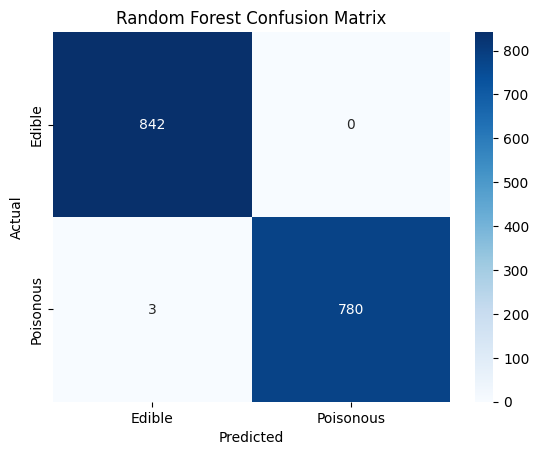

In [12]:
def evaluate_model(model, name):

    val_prob = model.predict_proba(X_val)[:, 1]

    # Find the highest threshold that gives
    # 100% poisonous recall on validation data
    thresholds = np.sort(np.unique(val_prob))

    valid_thresholds = []

    for threshold in thresholds:
        val_pred = (val_prob >= threshold).astype(int)

        sensitivity = recall_score(
            y_val, val_pred, pos_label=1
        )

        if sensitivity == 1.0:
            valid_thresholds.append(threshold)

    threshold = max(valid_thresholds) if valid_thresholds else 0

    # Evaluate on unseen test data
    test_prob = model.predict_proba(X_test)[:, 1]
    y_pred = (test_prob >= threshold).astype(int)

    print("\n", name)
    print("Threshold:", threshold)
    print("Accuracy:", accuracy_score(y_test, y_pred))
    print("Poisonous Sensitivity:",
          recall_score(y_test, y_pred, pos_label=1))

    print("\nClassification Report:")
    print(classification_report(
        y_test,
        y_pred,
        target_names=["Edible", "Poisonous"]
    ))

    cm = confusion_matrix(y_test, y_pred)

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Edible", "Poisonous"],
        yticklabels=["Edible", "Poisonous"]
    )

    plt.title(name + " Confusion Matrix")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.show()

    return threshold

dt_threshold = evaluate_model(
    dt_model, "Decision Tree"
)

rf_threshold = evaluate_model(
    rf_model, "Random Forest"
)

In [13]:
import joblib

joblib.dump(dt_model, "decision_tree_model.pkl")
joblib.dump(rf_model, "random_forest_model.pkl")

print("Models saved successfully!")

Models saved successfully!


In [14]:
sample = X_test.iloc[[0]]

prediction = rf_model.predict_proba(sample)[0][1]

if prediction >= rf_threshold:
    print("Prediction: Poisonous")
else:
    print("Prediction: Edible")

Prediction: Poisonous


In [15]:
!git config --global user.name "adhisiv"
!git config --global user.email "rsadhithyanjkm@gmail.com"

In [16]:
!git clone https://github.com/adhisiv/Mushroom-Classification.git

Cloning into 'Mushroom-Classification'...


In [25]:
import os
import shutil
import glob

# Search dynamically for any .ipynb file uploaded to /content
notebooks = glob.glob("/content/*.ipynb")
repo_path = "/content/Mushroom-Classification"

if notebooks:
    # Copy the first found notebook file to the repository folder
    src_notebook = notebooks[0]
    shutil.copy(src_notebook, repo_path)
    print(f"Success: '{os.path.basename(src_notebook)}' has been copied to the repository!")
else:
    print("Error: No .ipynb file found in /content.")
    print("Please go to File -> Download -> Download .ipynb, and then upload that file to the left-side file panel in Colab before running this cell again.")

Error: No .ipynb file found in /content.
Please go to File -> Download -> Download .ipynb, and then upload that file to the left-side file panel in Colab before running this cell again.
